<a href="https://colab.research.google.com/github/NatShed/MO_Attack/blob/main/lab15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лекция 12. Теория игр, состязательное обучение и безопасность MLOps

Курс «Глубокое обучение и безопасность нейронных сетей».
Лекция 12,13


## План

| Блок | Опыт | Что проверяем |
|---|---|---|
| A | Матричная zero-sum игра и LP | Смешанные стратегии, лучшие ответы, цена игры |
| B | Multiplicative weights | Средние стратегии и gap, а не только текущий loss |
| C | Bilinear GDA и extragradient | Равновесие существует, но динамика может расходиться |
| D | Stackelberg и tie-breaking | Порядок хода и наблюдаемость меняют решение |
| E | Настоящие маленькие нейросети | Матрица ошибок на development, аудит на test |
| F | Подпись и provenance локального артефакта | Доверенный ключ + digest + политика + тесты |
| G | Attention и очередь | Измеренная latency отдельно от симуляции обслуживания |
| H | Интеграл мощности и отчёт | Учебные данные энергии не являются измерением устройства |

Стенд не обращается к сервисам, не отправляет трафик, не загружает чужие модели и не запускает
опасную десериализацию. Длины attention ограничены 256, потоки CPU: 1.
Ни один опыт не является инструкцией по нагрузке чужой системы.


Семь программных заданий, интерпретация ML-эксперимента и итоговый отчёт. Заглушки None явно пропускают зависимые блоки; Run All без ошибок ещё не означает выполнения работы.

Zero-sum (игра с нулевой суммой) — это когда мы делим один пирог. Если один выиграл 10 долларов, значит, второй их потерял. В безопасности это упрощение: защитник теряет, атакующий получает ровно столько же.

Смешанная стратегия (Mixed strategy) — это когда ты не выбираешь одно действие, а делаешь его с какой-то вероятностью. Как в «Камень-Ножницы-Бумага»: если ты всегда кидаешь «Камень», тебя быстро раскусят. Поэтому ты рандомишь.

Равновесие Нэша (Nash Equilibrium) — это ситуация, когда ни одному игроку не выгодно менять свою стратегию в одностороннем порядке. Как в «Камне-Ножницах-Бумаге»: если ты рандомишь 33/33/33, соперник не может тебя обыграть.

Gap (Разрыв) — это показатель того, насколько текущая стратегия далека от идеала. Если Gap = 0, мы в идеальном равновесии.

Regret (Сожаление) — насколько сильно мы жалеем, что не выбрали одно и то же действие с самого начала. Если сожаление растет медленнее, чем количество шагов (no-regret), мы учимся.

GDA (Gradient Descent-Ascent) — обычный градиентный спуск (защитник) и подъем (атакующий).

Extragradient — «продвинутый» метод: сначала делает пробный шаг, чтобы посмотреть, куда всё катится, а потом корректирует курс.

Стекленберг (Stackelberg) — игра, где сначала ходит «лидер» (защитник), а «ведомый» (атакующий) отвечает лучшим ходом.

FGSM и PGD — алгоритмы, которые добавляют незаметный шум к картинке, чтобы нейросеть ошиблась.

AT (Adversarial Training) — защита: мы учим нейросеть на этих шумных (испорченных) картинках, чтобы она не ломалась.

Supply chain (Цепочка поставок) — путь модели от разработчика до сервера. Там можно подменить веса или внедрить вирус.

Latency (Задержка) — сколько времени сервер думает над ответом.

SLO (Service Level Objective) — обещание, сколько времени сервер должен отвечать (например, < 30 мс).

FCFS (First-Come, First-Served) — очередь, кто первый пришел, того первого и обслужили

Attention (Внимание) — механизм в нейросетях, который «смотрит» на все части текста одновременно (сложность растет квадратично от длины).

In [ ]:
# При необходимости установите и перезапустите ядро:
# %pip install numpy scipy pandas matplotlib torch scikit-learn cryptography
import time, json, hashlib, copy, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from scipy.special import softmax
import scipy, sklearn, cryptography
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
from cryptography.exceptions import InvalidSignature
from IPython.display import display

START=time.perf_counter()
SEED=42
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({"figure.figsize":(8,4),"font.size":10})
versions={"python":platform.python_version(),"torch":torch.__version__,
          "numpy":np.__version__,"scipy":scipy.__version__,"sklearn":sklearn.__version__,
          "cryptography":cryptography.__version__,"device":"CPU","threads":1}
print(versions)
results={"environment":versions}
completed=[]
def pending(s): print(f"{s}: не выполнено, реализуйте TODO.")

{'python': '3.13.16', 'torch': '2.11.0+cpu', 'numpy': '2.1.3', 'scipy': '1.16.3', 'sklearn': '1.6.1', 'cryptography': '50.0.2', 'device': 'CPU', 'threads': 1}


## A. Zero-sum игра: защитник минимизирует, атакующий максимизирует

Строки A: политики защитника, столбцы: стратегии атакующего.
Числа ниже являются СКОНСТРУИРОВАННЫМ учебным ущербом, а не вероятностями реальных атак.
При \(p\in\Delta_m,\ q\in\Delta_n\) ожидаемый ущерб \(p^\top A q\).
LP и minimax: [CMU, Computational Game Solving](https://www.andrew.cmu.edu/user/ianagnos/lecture_notes-cmu15888/L4.pdf).

In [ ]:
A=np.array([[1.,5.],[4.,2.]])
defenses=["Inspect supply chain","Limit serving cost"]
attacks=["Artifact attack","Expensive request"]
display(pd.DataFrame(A,index=defenses,columns=attacks))
print("Наихудший ущерб каждой чистой защиты:",A.max(axis=1))
print("Лучшая чистая защита:",defenses[int(A.max(axis=1).argmin())])

,Artifact attack,Expensive request
Inspect supply chain,1.0,5.0
Limit serving cost,4.0,2.0


Наихудший ущерб каждой чистой защиты: [5. 4.]
Лучшая чистая защита: Limit serving cost


Игра 2x2
Таблица: Защитник хочет уменьшить ущерб, Атакующий — увеличить.

Если защитник выберет лучшую «чистую» (одну) стратегию «Limit serving cost», атакующий ответит «Artifact attack» (ущерб 4). Если защитник выберет «Inspect», атакующий выберет «Expensive request» (ущерб 5).

### Задание A1. Линейные программы
Реализуйте `solve_zero_sum(A)`, возвращающую p, q, v.
Для защитника минимизируйте v при A.T @ p <= v и sum(p)=1.
Для атакующего максимизируйте w при A @ q >= w и sum(q)=1.
Скалярные v,w должны быть свободными по знаку; вероятности неотрицательны.
Проверяйте success решателя и совпадение цен primal/dual.

In [ ]:
def solve_zero_sum(A):
    A = np.asarray(A, dtype=float)
    m, n = A.shape
    # --- Защитник: minimize v, vars = [p_1..p_m, v] ---
    c_def = np.zeros(m + 1); c_def[-1] = 1.0
    A_ub_def = np.zeros((n, m + 1))
    A_ub_def[:, :m] = A.T               # A^T p
    A_ub_def[:, m]  = -1.0              # - v <= 0
    b_ub_def = np.zeros(n)
    A_eq_def = np.zeros((1, m + 1)); A_eq_def[0, :m] = 1.0
    b_eq_def = np.array([1.0])
    bounds_def = [(0, None)] * m + [(None, None)]
    r_def = linprog(c_def, A_ub=A_ub_def, b_ub=b_ub_def,
                    A_eq=A_eq_def, b_eq=b_eq_def,
                    bounds=bounds_def, method="highs")
    if not r_def.success:
        return None
    # --- Атакующий: maximize w <=> minimize -w, vars = [q_1..q_n, w] ---
    c_att = np.zeros(n + 1); c_att[-1] = -1.0
    A_ub_att = np.zeros((m, n + 1))
    A_ub_att[:, :n] = -A                # -A q
    A_ub_att[:, n]  = 1.0               # + w <= 0  =>  A q >= w
    b_ub_att = np.zeros(m)
    A_eq_att = np.zeros((1, n + 1)); A_eq_att[0, :n] = 1.0
    b_eq_att = np.array([1.0])
    bounds_att = [(0, None)] * n + [(None, None)]
    r_att = linprog(c_att, A_ub=A_ub_att, b_ub=b_ub_att,
                    A_eq=A_eq_att, b_eq=b_eq_att,
                    bounds=bounds_att, method="highs")
    if not r_att.success:
        return None
    p, v = r_def.x[:m], r_def.x[m]
    q, w = r_att.x[:n], r_att.x[n]
    if not np.isclose(v, w, atol=1e-6):   # primal/dual consistency
        return None
    return p, q, v

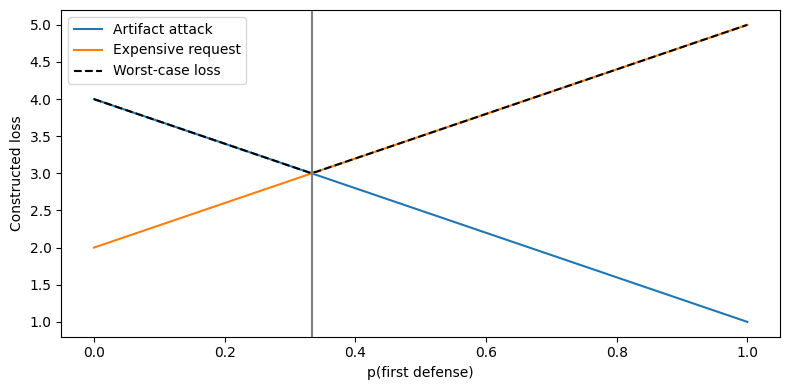

{'p': [0.3333333333333333, 0.6666666666666667], 'q': [0.5, 0.5], 'value': np.float64(3.0000000000000004), 'gap': 4.440892098500626e-16}


In [ ]:
def game_gap(A,p,q):
    upper=np.max(p@A)
    lower=np.min(A@q)
    return float(upper-lower),float(lower),float(upper)

equilibrium=solve_zero_sum(A)
if equilibrium is None:
    pending("A1")
else:
    p,q,v=equilibrium
    np.testing.assert_allclose(p,[1/3,2/3],atol=1e-8)
    np.testing.assert_allclose(q,[.5,.5],atol=1e-8)
    assert np.isclose(v,3) and game_gap(A,p,q)[0]<1e-8
    for matrix in [A-10,np.array([[2.,2.],[2.,2.]])]:
        pp,qq,vv=solve_zero_sum(matrix)
        assert (pp>=-1e-9).all() and (qq>=-1e-9).all()
        assert np.isclose(pp.sum(),1) and np.isclose(qq.sum(),1)
        assert game_gap(matrix,pp,qq)[0]<1e-8
    grid=np.linspace(0,1,101)
    curves=np.array([np.array([r,1-r])@A for r in grid])
    plt.plot(grid,curves[:,0],label=attacks[0]);plt.plot(grid,curves[:,1],label=attacks[1])
    plt.plot(grid,curves.max(axis=1),"k--",label="Worst-case loss")
    plt.axvline(p[0],color="gray");plt.xlabel("p(first defense)");plt.ylabel("Constructed loss")
    plt.legend();plt.tight_layout();plt.show()
    results["matrix_game"]={"p":p.tolist(),"q":q.tolist(),"value":v,"gap":game_gap(A,p,q)[0]}
    completed.append("A")
    print(results["matrix_game"])

Синяя и оранжевая линии — это ущерб. Нам нужно найти нижнюю точку на черном пунктире (худший случай). Это пересечение ровно посередине.

Результат: p = [0.333, 0.666] (1/3 и 2/3), q = [0.5, 0.5]. Цена игры v = 3. Gap = 0. То есть, смешивая действия, защитник снижает гарантированный ущерб с 4 до 3

## B. Повторяемая игра и no-regret learning

Используем full-information feedback: после раунда доступны потери ВСЕХ действий, не только сыгранного.
Обновления обоих игроков вычисляются по старым p_t,q_t одновременно.
Для защитника log-weights уменьшаются на \(\eta A q_t\), для атакующего увеличиваются на \(\eta A^\top p_t\).
Анализ no-regret и усреднения в zero-sum играх: [CMU](https://www.andrew.cmu.edu/user/ianagnos/lecture_notes-cmu15888/L4.pdf).

### Задание B1. Одновременное обновление log-weights

Верните две новые копии log-weights. Знаки различны, потому что один игрок минимизирует,
другой максимизирует. Нельзя использовать уже обновлённое p при расчёте второго игрока.

In [ ]:
def mwu_step(logp,logq,A,eta):
    # TODO: старые softmax-стратегии, разные знаки, стабилизация вычитанием max.
    p = softmax(logp)
    q = softmax(logq)
    loss_d = A @ q           # length m: потери защитника по строкам
    gain_a = A.T @ p         # length n: выигрыш атакующего по столбцам
    new_logp = logp - eta * loss_d
    new_logq = logq + eta * gain_a
    # Стабилизация — вычитание max не меняет softmax
    new_logp = new_logp - new_logp.max()
    new_logq = new_logq - new_logq.max()
    return new_logp, new_logq

,T,eta,average_p,average_q,average_gap,defender_regret,attacker_regret
0,4000,0.004743,"[0.32525560926467356, 0.6747443907353288]","[0.5044112915854072, 0.4955887084145925]",0.041878,23.401679,144.111675


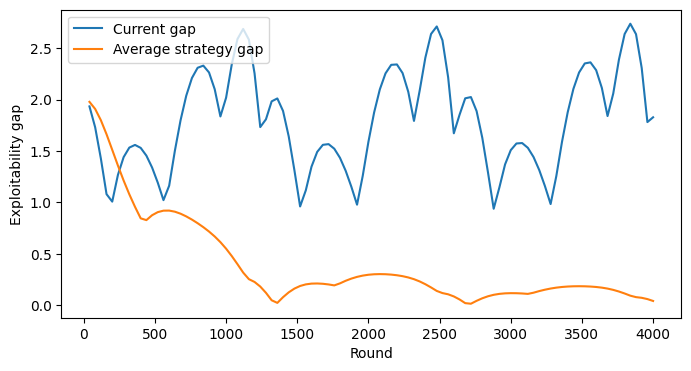

In [ ]:
probe=mwu_step(np.zeros(2),np.zeros(2),A,.01)
if probe is None:
    pending("B1")
else:
    testp,testq=mwu_step(np.zeros(2),np.zeros(2),A,.2)
    # Потери строк при uniform: 3 и 3, поэтому p остаётся uniform.
    np.testing.assert_allclose(softmax(testp),[.5,.5])
    assert softmax(testq)[1]>.5  # payoff columns: 2.5 и 3.5
    T=4000; eta=.3/np.sqrt(T)
    lp=np.log([.8,.2]);lq=np.log([.2,.8])
    ps=[];qs=[];losses=[];hist=[]
    for t in range(T):
        pp,qq=softmax(lp),softmax(lq)
        ps.append(pp);qs.append(qq);losses.append(pp@A@qq)
        lp,lq=mwu_step(lp,lq,A,eta)
        if (t+1)%40==0:
            pm,qm=np.mean(ps,axis=0),np.mean(qs,axis=0)
            hist.append({"round":t+1,"current_gap":game_gap(A,pp,qq)[0],
                         "average_gap":game_gap(A,pm,qm)[0]})
    P,Q=np.array(ps),np.array(qs)
    reg_d=np.sum(losses)-np.min((A@Q.T).sum(axis=1))
    reg_a=np.max((P@A).sum(axis=0))-np.sum(losses)
    gap=game_gap(A,P.mean(0),Q.mean(0))[0]
    assert np.isclose((reg_d+reg_a)/T,gap,atol=1e-10)
    results["mwu"]={"T":T,"eta":eta,"average_p":P.mean(0).tolist(),"average_q":Q.mean(0).tolist(),
                    "average_gap":gap,"defender_regret":float(reg_d),"attacker_regret":float(reg_a)}
    display(pd.DataFrame([results["mwu"]]))
    h=pd.DataFrame(hist)
    plt.plot(h["round"],h.current_gap,label="Current gap")
    plt.plot(h["round"],h.average_gap,label="Average strategy gap")
    plt.xlabel("Round");plt.ylabel("Exploitability gap");plt.legend();plt.show()
    completed.append("B")

Игроки играют 4000 раз и обновляют вероятности (Multiplicative Weights).

График: Синяя линия (текущий gap) скачет. Оранжевая (средняя) плавно спускается вниз почти к нулю.

В реальном времени стратегии могут «танцевать» (циклиться), но если усреднить их за все раунды, мы получим почти идеальное равновесие (gap ~ 0.04). Средние стратегии p ≈ [0.325, 0.674] очень близки к идеалу (1/3, 2/3).

## C. Почему минимакс не гарантирует сходимость градиентов

Изучаем $ \min_x\max_y xy $ на R², равновесие (0,0).

Одновременный GDA: $\($x'=x-\eta y,\ y'=y+\eta x$.

Длина вектора увеличивается в $\sqrt{1+\eta^2}$ раза.

Extragradient сначала делает пробный шаг, затем вычисляет обновление из исходной точки по градиенту в пробной. Это аналитический учебный пример, не обучение GAN.

### Задание C1. Extra-gradient step

Сначала вычислите x_mid=x-eta*y и y_mid=y+eta*x.
Затем обновите исходные x,y градиентом в середине; не делайте второй шаг из mid.

In [ ]:
def extra_step(x,y,eta):
    # TODO: пробный шаг и коррекция из исходной точки.
    x_mid = x - eta * y
    y_mid = y + eta * x
    x_new = x - eta * y_mid
    y_new = y + eta * x_mid
    return x_new, y_new

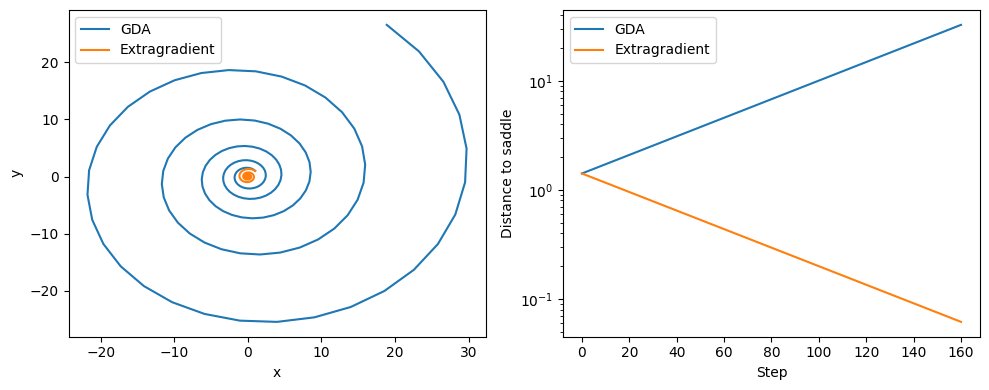

In [ ]:
if extra_step(1.,1.,.2) is None:
    pending("C1")
else:
    eta=.2;steps=160
    gd=np.array([1.,1.]);eg=gd.copy()
    gd_path=[gd.copy()];eg_path=[eg.copy()]
    for _ in range(steps):
        x,y=gd
        gd=np.array([x-eta*y,y+eta*x])
        eg=np.array(extra_step(*eg,eta))
        gd_path.append(gd.copy());eg_path.append(eg.copy())
    gd_path,eg_path=np.array(gd_path),np.array(eg_path)
    ng=np.linalg.norm(gd_path,axis=1);ne=np.linalg.norm(eg_path,axis=1)
    np.testing.assert_allclose(ng[1]/ng[0],np.sqrt(1+eta**2))
    np.testing.assert_allclose(ne[1]/ne[0],np.sqrt((1-eta**2)**2+eta**2))
    assert ng[-1]>ng[0] and ne[-1]<ne[0]
    fig,ax=plt.subplots(1,2,figsize=(10,4))
    ax[0].plot(gd_path[:,0],gd_path[:,1],label="GDA")
    ax[0].plot(eg_path[:,0],eg_path[:,1],label="Extragradient")
    ax[0].set(xlabel="x",ylabel="y");ax[0].legend()
    ax[1].semilogy(ng,label="GDA");ax[1].semilogy(ne,label="Extragradient")
    ax[1].set(xlabel="Step",ylabel="Distance to saddle");ax[1].legend()
    plt.tight_layout();plt.show()
    results["bilinear"]={"eta":eta,"steps":steps,"GDA_final_norm":float(ng[-1]),
                         "extragradient_final_norm":float(ne[-1])}
    completed.append("C")

GDA (Gradient Descent-Ascent) — обычный градиентный спуск (защитник) и подъем (атакующий).

Extragradient — «продвинутый» метод: сначала делает пробный шаг, чтобы посмотреть, куда всё катится, а потом корректирует курс.

 GDA (синяя) крутится по спирали и улетает в бесконечность (расходится). Extragradient (оранжевая) крутится и затягивается в центр (сходится).

 Второй график: Синяя линия растет (GDA удаляется от равновесия), оранжевая падает (Extragradient приближается).

 Наличие равновесия (центра) не значит, что простой алгоритм (GDA) его найдет. Нужен умный алгоритм.

## D. Stackelberg: сначала обязательство, затем лучший ответ

Защитник публикует вероятность p проверки артефактов, но атакующий не видит исход случайной проверки
до выбора атаки. Это наблюдение ПОЛИТИКИ, не реализации действия.
Все utility ниже условны и сконструированы.

Выгода атакующего: U_artifact=6-8p, U_latency=2+2p, U_abstain=0.
Потери защитника: L_artifact=8-5p, L_latency=2+2p, L_abstain=p.
В отличие от zero-sum игры, потери защитника не равны выгоде атакующего.
При равных лучших ответах сравниваем благоприятное и неблагоприятное для защитника разрешение ничьей
([Stackelberg security games](https://bc.itl.waw.pl/Content/1933/ISSN_1509-4553_3_2016_70.pdf)).

### Задание D1. Ответ последователя и tie-breaking

Выберите все действия с максимальной U_attacker в пределах atol.
Из них при favorable выберите минимум L_defender, при pessimistic максимум.
Верните индекс выбранного действия; минимизировать L по всем действиям атакующего нельзя.

In [ ]:
def follower_response(attacker_util,defender_loss,tie="pessimistic",atol=1e-10):
    # TODO: сначала best-response set по utility атакующего, потом tie-breaking.
    au = np.asarray(attacker_util)
    dl = np.asarray(defender_loss)
    max_u = au.max()
    br_set = np.flatnonzero(np.abs(au - max_u) <= atol)
    if tie == "favorable":
        return int(br_set[np.argmin(dl[br_set])])
    else:  # pessimistic
        return int(br_set[np.argmax(dl[br_set])])

,p,tie,action,defender_loss
0,0.400,favorable,1,2.800
1,0.401,pessimistic,1,2.802


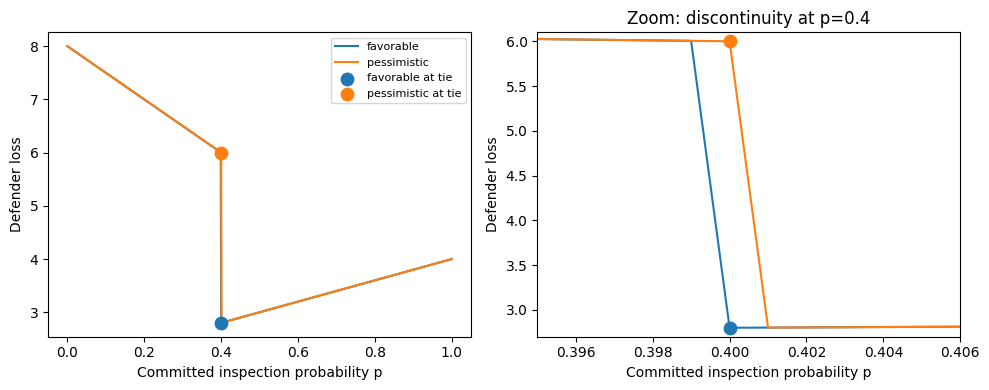

Решение по сетке НЕ объявляется точным непрерывным pessimistic equilibrium.
При p=0.4 utility равны; unfavorable loss=6. Для p>0.4 loss=2+2p.
Pessimistic infimum 2.8 приближается справа, но в непрерывной задаче не достигается.


In [ ]:
if follower_response(np.array([1.,1.]),np.array([5.,2.])) is None:
    pending("D1")
else:
    assert follower_response(np.array([1.,1.]),np.array([5.,2.]),"favorable")==1
    assert follower_response(np.array([1.,1.]),np.array([5.,2.]),"pessimistic")==0
    rows=[]
    grid=np.linspace(0,1,1001)
    for pp in grid:
        au=np.array([6-8*pp,2+2*pp,0.])
        dl=np.array([8-5*pp,2+2*pp,pp])
        for tie in ["favorable","pessimistic"]:
            j=follower_response(au,dl,tie)
            rows.append({"p":pp,"tie":tie,"action":j,"defender_loss":dl[j]})
    sdf=pd.DataFrame(rows)
    selected=sdf.loc[sdf.groupby("tie").defender_loss.idxmin()].reset_index(drop=True)
    display(selected)
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    for ax in axes:
        for tie in ["favorable","pessimistic"]:
            sub=sdf[sdf.tie==tie]
            ax.plot(sub.p,sub.defender_loss,label=tie)
        ax.scatter([.4],[2.8],s=80,color="tab:blue",zorder=5,label="favorable at tie")
        ax.scatter([.4],[6.],s=80,color="tab:orange",zorder=5,label="pessimistic at tie")
        ax.set(xlabel="Committed inspection probability p",ylabel="Defender loss")
    axes[1].set_xlim(.395,.406);axes[1].set_ylim(2.7,6.1)
    axes[0].legend(fontsize=8);axes[1].set_title("Zoom: discontinuity at p=0.4")
    plt.tight_layout();plt.show()
    print("Решение по сетке НЕ объявляется точным непрерывным pessimistic equilibrium.")
    print("При p=0.4 utility равны; unfavorable loss=6. Для p>0.4 loss=2+2p.")
    print("Pessimistic infimum 2.8 приближается справа, но в непрерывной задаче не достигается.")
    results["stackelberg_grid"]=selected.to_dict("records")
    completed.append("D")

 Защитник фиксирует вероятность проверки p.

График (Слева): Оранжевая линия — защитник думает пессимистично (атакующий выберет худшее). Синяя — оптимистично. В точке p = 0.4 происходит «излом» (атакующему становится неважно, что делать).

График (Справа, Zoom): Видно, что при p = 0.4 ущерб равен 2.8 (оптимистично), но если защитник чуть-чуть перестрахуется (p = 0.401), ущерб подскакивает до 2.8 + чуть-чуть. Вывод: порядок хода и правило разрешения ничьей меняют ответ.

## E. От игры к настоящей нейросети: матрица измеренных ошибок

Обучаем три маленькие MLP на локальных цифрах: ERM, noise augmentation и adversarial training.
Столбцы матрицы: random L∞ perturbation, FGSM и PGD. Все радиусы 0.10 в [0,1].
Каждая ячейка использует white-box доступ к соответствующей строке-модели.

Это ограниченная игра между БИБЛИОТЕКАМИ политик. Атакующий заранее выбирает алгоритм,
затем этот алгоритм может работать с выбранной моделью. Это не сертификат против всех адаптивных атак
и не утверждение о безопасности скрытого случайного роутинга.

Вероятности защитника выбираются только по development-матрице; test используется после фиксации p.
Доминирование одного столбца и чистое оптимальное решение являются допустимым результатом.

DEVELOPMENT loss matrix


,random,FGSM,PGD
ERM,0.025000,0.491667,0.533333
Noise,0.025000,0.416667,0.483333
AT,0.066667,0.275000,0.283333


TEST loss matrix; p не переоптимизируется


,random,FGSM,PGD
ERM,0.041667,0.483333,0.516667
Noise,0.033333,0.450000,0.491667
AT,0.041667,0.216667,0.250000


p_fixed = [0. 0. 1.] ; test loss by column = [0.04166669 0.21666664 0.25      ]


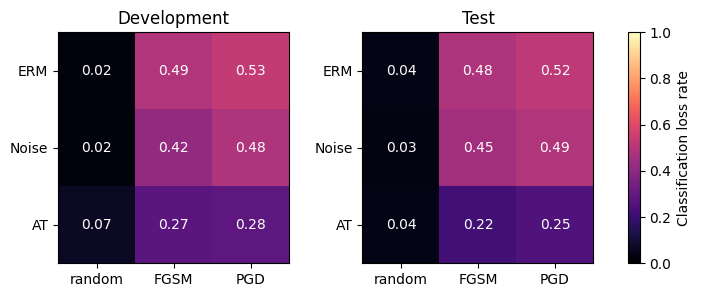

In [ ]:
digits=load_digits()
X=(digits.data/16).astype(np.float32);Y=digits.target
rest,test_ids=train_test_split(np.arange(len(Y)),test_size=500,random_state=10,stratify=Y)
train_ids,dev_ids=train_test_split(rest,train_size=900,random_state=11,stratify=Y[rest])
dev_audit,_=train_test_split(dev_ids,train_size=120,random_state=12,stratify=Y[dev_ids])
test_audit,_=train_test_split(test_ids,train_size=120,random_state=13,stratify=Y[test_ids])
assert not set(dev_ids)&set(test_ids) and not set(train_ids)&set(test_ids)
xt=torch.tensor(X[train_ids]);yt=torch.tensor(Y[train_ids],dtype=torch.long)
def model_new(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(64,32),nn.ReLU(),nn.Linear(32,10))
def project(z,x,eps):
    return torch.maximum((x-eps).clamp(0,1),torch.minimum(z,(x+eps).clamp(0,1)))
def attack(model,x,y,kind,seed=42):
    eps=.1;gen=torch.Generator().manual_seed(seed)
    if kind=="random":
        return project(x+eps*(2*torch.rand(x.shape,generator=gen)-1),x,eps)
    z=x.clone() if kind=="FGSM" else project(x+eps*(2*torch.rand(x.shape,generator=gen)-1),x,eps)
    steps=1 if kind=="FGSM" else 15
    step=.1 if kind=="FGSM" else .02
    with torch.no_grad():
        best=x.clone();bestloss=F.cross_entropy(model(best),y,reduction="none")
        bestbad=model(best).argmax(1)!=y
    for _ in range(steps):
        z.requires_grad_(True)
        grad=torch.autograd.grad(F.cross_entropy(model(z),y),z)[0]
        z=project(z.detach()+step*grad.sign(),x,eps).detach()
        with torch.no_grad():
            logits=model(z);bad=logits.argmax(1)!=y
            loss=F.cross_entropy(logits,y,reduction="none")
            use=(bad&~bestbad)|((bad==bestbad)&(loss>bestloss))
            best[use]=z[use];bestloss[use]=loss[use];bestbad[use]=bad[use]
    return best

networks={}
for mode in ["ERM","Noise","AT"]:
    m=model_new(70)
    opt=torch.optim.Adam(m.parameters(),lr=.01,weight_decay=1e-4)
    gen=torch.Generator().manual_seed(71)
    for epoch in range(90):
        if mode=="Noise": train_x=(xt+.1*torch.randn(xt.shape,generator=gen)).clamp(0,1)
        elif mode=="AT": train_x=attack(m,xt,yt,"FGSM",seed=epoch)
        else: train_x=xt
        opt.zero_grad()
        loss=F.cross_entropy(m(train_x),yt)
        loss.backward();opt.step()
    networks[mode]=m.eval()

def payoff_matrix(indices):
    x=torch.tensor(X[indices]);y=torch.tensor(Y[indices],dtype=torch.long)
    matrix=np.zeros((3,3))
    for i,(name,m) in enumerate(networks.items()):
        with torch.no_grad(): clean_ok=m(x).argmax(1)==y
        for j,kind in enumerate(["random","FGSM","PGD"]):
            adv=attack(m,x,y,kind,seed=80)
            assert (adv-x).abs().max()<=.100001
            with torch.no_grad(): ok=m(adv).argmax(1)==y
            # Включаем исходный вход, поэтому чистые ошибки не "исправляются" атакой.
            matrix[i,j]=1-(ok&clean_ok).float().mean().item()
    return matrix
dev_matrix=payoff_matrix(dev_audit)
print("DEVELOPMENT loss matrix");display(pd.DataFrame(dev_matrix,index=list(networks),columns=["random","FGSM","PGD"]))
if solve_zero_sum(dev_matrix) is None:
    pending("E: нужен A1")
else:
    pdev,qdev,vdev=solve_zero_sum(dev_matrix)  # фиксируем до test
    test_matrix=payoff_matrix(test_audit)
    test_expected=pdev@test_matrix
    results["empirical_game"]={"development":dev_matrix.tolist(),"p_fixed":pdev.tolist(),
                               "q_development":qdev.tolist(),"development_value":vdev,
                               "test":test_matrix.tolist(),"test_expected_loss_by_attack":test_expected.tolist(),
                               "test_worst_library_loss":float(test_expected.max())}
    print("TEST loss matrix; p не переоптимизируется")
    display(pd.DataFrame(test_matrix,index=list(networks),columns=["random","FGSM","PGD"]))
    print("p_fixed =",pdev,"; test loss by column =",test_expected)
    fig,ax=plt.subplots(1,2,figsize=(9,3))
    for a,matrix,title in zip(ax,[dev_matrix,test_matrix],["Development","Test"]):
        im=a.imshow(matrix,vmin=0,vmax=1,cmap="magma")
        a.set_xticks(range(3),["random","FGSM","PGD"])
        a.set_yticks(range(3),list(networks));a.set_title(title)
        for i in range(3):
            for j in range(3): a.text(j,i,f"{matrix[i,j]:.2f}",ha="center",va="center",color="white" if matrix[i,j]<.6 else "black")
    fig.colorbar(im,ax=ax.ravel().tolist(),label="Classification loss rate")
    plt.show();completed.append("E")

Слева (Development): Мы тестируем 3 модели (ERM, Noise, AT) против 3 атак (random, FGSM, PGD). Видно, что AT (Adversarial Training) самая крутая — ее потери (0.27 - 0.28) намного меньше, чем у ERM (0.49 - 0.53).

Справа (Test): Мы зафиксировали выбор (AT) на development и проверили на новых данных. Результат тот же: AT лучшая (0.22 - 0.25). Это доказывает, что модель не просто «зазубрила» тест, а реально научилась защищаться.

Итог: Оптимальная стратегия — 100% ставить AT (чистая стратегия).

## F. Supply chain: подпись, digest, политика и поведенческая проверка

Используем маленький JSON с числовыми весами, НЕ pickle и НЕ исполняемый checkpoint.
Ключ Ed25519 создаётся локально только для учебной подписи; не сохраняется и не отправляется.
Verifier получает только public key через доверенную конфигурацию, не из приложенного артефакта.
Подписывается canonical JSON-манифест с SHA-256 артефакта, builder, source, release и dependencies.

Это мини-протокол, НЕ реализация SLSA/in-toto и не присвоение уровня SLSA.
Смысл проверок соответствует [SLSA verification](https://slsa.dev/spec/v1.2/verifying-artifacts).
Сведения о компонентах и данных полезны, но не заменяют их проверку
([NIST SP 800-218A](https://nvlpubs.nist.gov/nistpubs/SpecialPublications/NIST.SP.800-218A.pdf)).

In [ ]:
def canonical(obj):
    return json.dumps(obj,sort_keys=True,separators=(",",":"),allow_nan=False).encode("utf-8")
def digest(blob): return hashlib.sha256(blob).hexdigest()
signer=Ed25519PrivateKey.generate()
trusted_public=signer.public_key()
attacker_signer=Ed25519PrivateKey.generate()
artifact=canonical({"weights":[[2.,-2.],[-2.,2.]],"bias":[0.,0.]})
expected_policy={"builder":"local-course-builder","source":"course/approved-model",
                 "commit":"revision-002","release":2,"dependencies":{"lab-runtime":"1.0"}}
manifest={**expected_policy,"sha256":digest(artifact),"format":"numeric-json-v1"}
signature=signer.sign(canonical(manifest))

### Задание F1. Admission gate артефакта (15 баллов)

Сначала ограничьте размер bytes 16 KiB, затем проверьте подпись canonical(manifest) доверенным public key.
Проверьте digest, точное совпадение builder/source/commit/release/dependencies и format.
Отклоните неизвестные поля. Верните (True,"verified") или (False,reason).
Частный ключ signer НЕ должен использоваться внутри verifier.

In [ ]:
def verify_artifact(blob, meta, sig, public_key, policy):
    # 1. Размер
    if len(blob) > 16 * 1024:
        return False, "artifact_too_large"
    # 2. Схема: ровно ожидаемые поля
    allowed = {"builder", "source", "commit", "release",
               "dependencies", "sha256", "format"}
    if set(meta.keys()) != allowed:
        return False, "schema"
    # 3. Формат
    if meta.get("format") != "numeric-json-v1":
        return False, "format"
    # 4. Подпись
    try:
        public_key.verify(sig, canonical(meta))
    except InvalidSignature:
        return False, "signature"
    # 5. Digest
    if meta.get("sha256") != digest(blob):
        return False, "digest"
    # 6. Политика
    for key in ("builder", "source", "commit", "release", "dependencies"):
        if meta.get(key) != policy.get(key):
            return False, f"policy_{key}"
    return True, "verified"

In [ ]:
def safe_numeric_parse(blob):
    obj=json.loads(blob)
    if set(obj)!={"weights","bias"}: raise ValueError("unexpected model fields")
    W=np.asarray(obj["weights"],dtype=float);b=np.asarray(obj["bias"],dtype=float)
    if W.shape!=(2,2) or b.shape!=(2,): raise ValueError("shape")
    if not np.isfinite(W).all() or not np.isfinite(b).all(): raise ValueError("non-finite")
    if np.abs(W).max()>10 or np.abs(b).max()>10: raise ValueError("numeric range")
    return W,b
def smoke_score(W,b):
    x=np.array([[1.,0.],[.8,.2],[0.,1.],[.2,.8]])
    y=np.array([0,0,1,1])
    return float(((x@W.T+b).argmax(1)==y).mean())
def release_gate(blob,meta,sig):
    verdict=verify_artifact(blob,meta,sig,trusted_public,expected_policy)
    if verdict is None: return None
    ok,reason=verdict
    if not ok: return False,reason,None
    try: W,b=safe_numeric_parse(blob)
    except (ValueError,TypeError,KeyError): return False,"numeric_schema",None
    score=smoke_score(W,b)
    return score>=1.0, "release_candidate" if score>=1.0 else "behavior_test",score

if verify_artifact(artifact,manifest,signature,trusted_public,expected_policy) is None:
    pending("F1")
else:
    changed=canonical({"weights":[[-2.,2.],[2.,-2.]],"bias":[0.,0.]})
    updated={**manifest,"sha256":digest(changed)}
    wrong_source={**manifest,"source":"course/unapproved-fork"}
    stale={**manifest,"release":1}
    cases=[
        ("valid",artifact,manifest,signature,True),
        ("changed weights",changed,manifest,signature,False),
        ("changed digest without signature",changed,updated,signature,False),
        ("untrusted self-signer",artifact,manifest,attacker_signer.sign(canonical(manifest)),False),
        ("signed wrong source",artifact,wrong_source,signer.sign(canonical(wrong_source)),False),
        ("signed stale release",artifact,stale,signer.sign(canonical(stale)),False),
        ("trusted signer, bad behavior",changed,updated,signer.sign(canonical(updated)),False)]
    gate_rows=[]
    for name,blob,meta,sig,expected in cases:
        admitted,reason,score=release_gate(blob,meta,sig)
        assert admitted==expected,(name,reason)
        gate_rows.append({"scenario":name,"admitted":bool(admitted),"reason":reason,"smoke_accuracy":score})
    results["release_gate"]=gate_rows;display(pd.DataFrame(gate_rows));completed.append("F")
    print("PASS != отсутствие backdoor. Четыре smoke-примера проверяют только узкую известную спецификацию.")
    print("Все подписи созданы внутри локального стенда; реальные production-ключи не используются.")

,scenario,admitted,reason,smoke_accuracy
0,valid,True,release_candidate,1.0
1,changed weights,False,digest,NaN
2,changed digest without signature,False,signature,NaN
3,untrusted self-signer,False,signature,NaN
4,signed wrong source,False,policy_source,NaN
5,signed stale release,False,policy_release,NaN
6,"trusted signer, bad behavior",False,behavior_test,0.0


PASS != отсутствие backdoor. Четыре smoke-примера проверяют только узкую известную спецификацию.
Все подписи созданы внутри локального стенда; реальные production-ключи не используются.


Supply chain: Мы подписали файл ключом. Проверка отвергла 6 плохих сценариев (подмена весов, подмена подписи, левый ключ, неверный код, устаревший релиз, плохое поведение) и пропустила только 1 хороший.

## G. Latency: локальная ограниченная нагрузка и отдельная симуляция очереди

Sponge examples направлены на затраты и задержки, а не обязательно на ошибочную метку
([Shumailov et al.](https://arxiv.org/abs/2006.03463)).
Ниже измеряется только локальная CPU-latency attention для фиксированного набора длин.
Это workload stress demonstration, НЕ оптимизированная sponge-атака на промышленную модель.
Энергия устройства не измеряется. Dense attention не становится дешевле просто из-за нулевых значений.

,tokens,median_ms,p95_ms,timing_windows,MAC_QK_AV,attention_score_bytes_float32
0,32,0.025718,0.040807,31,65536,4096
1,64,0.036832,0.050617,31,262144,16384
2,128,0.076750,0.088243,31,1048576,65536
3,256,0.229232,0.255483,31,4194304,262144


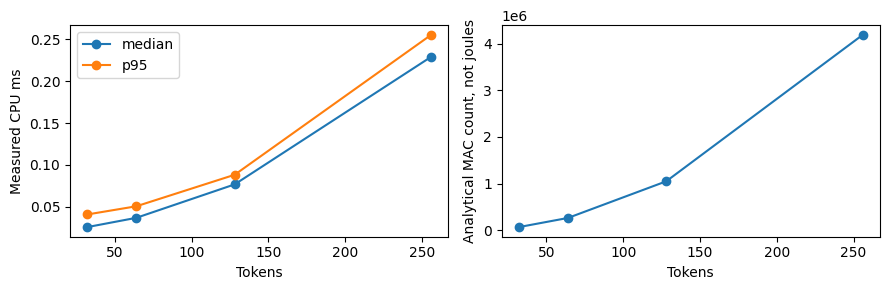

p95 относится к среднему из 5 операций в окне, не к p95 сетевого сервиса.


In [ ]:
LENGTHS=[32,64,128,256]
D=32
hard_limit=256
def attention(q,k,v):
    return torch.softmax(q@k.T/np.sqrt(D),dim=-1)@v
gen=torch.Generator().manual_seed(99)
inputs={L:tuple(torch.randn((L,D),generator=gen) for _ in range(3)) for L in LENGTHS}
assert max(LENGTHS)<=hard_limit
measurements={L:[] for L in LENGTHS}
rounds=31
with torch.inference_mode():
    for L in LENGTHS:
        for _ in range(6): attention(*inputs[L])
    rng=np.random.default_rng(101)
    for _ in range(rounds):
        for L in rng.permutation(LENGTHS):
            t0=time.perf_counter_ns()
            for _ in range(5): attention(*inputs[L])
            ns=(time.perf_counter_ns()-t0)/5
            measurements[L].append(ns/1e6)
latency_rows=[]
for L in LENGTHS:
    a=np.array(measurements[L])
    latency_rows.append({"tokens":L,"median_ms":float(np.median(a)),"p95_ms":float(np.quantile(a,.95)),
                         "timing_windows":rounds,"MAC_QK_AV":2*L*L*D,
                         "attention_score_bytes_float32":L*L*4})
results["local_latency"]=latency_rows
display(pd.DataFrame(latency_rows))
fig,ax=plt.subplots(1,2,figsize=(9,3))
df=pd.DataFrame(latency_rows)
ax[0].plot(df.tokens,df.median_ms,"o-",label="median")
ax[0].plot(df.tokens,df.p95_ms,"o-",label="p95")
ax[0].set(xlabel="Tokens",ylabel="Measured CPU ms");ax[0].legend()
ax[1].plot(df.tokens,df.MAC_QK_AV,"o-")
ax[1].set(xlabel="Tokens",ylabel="Analytical MAC count, not joules")
plt.tight_layout();plt.show()
print("p95 относится к среднему из 5 операций в окне, не к p95 сетевого сервиса.")

Слева (Время): Токенов от 32 до 256. Время растет, но не в 64 раза (как количество операций), а где-то в 9 раз (из-за накладных расходов).

Справа (MACs): Аналитическое количество операций. Оно растет идеально в квадрате (в 64 раза).

### Задание G1. Проверка входного бюджета до expensive compute (10 баллов)

Верните (admit, reason, token_count).
Проверьте размер UTF-8 bytes ДО split, затем число whitespace-токенов.
Учебный token counter не является tokenizer LLM. Не выполняйте attention для отклонённых запросов.

In [ ]:
def admit_request(text,max_bytes=4096,max_tokens=128):
    # TODO: тип, bytes, пустота, token cap; никаких сетевых вызовов.
    if not isinstance(text, str):
        return False, "type", 0
    blob = text.encode("utf-8")
    if len(blob) > max_bytes:
        return False, "bytes", 0
    tokens = text.split()
    if len(tokens) == 0:
        return False, "empty", 0
    if len(tokens) > max_tokens:
        return False, "tokens", len(tokens)
    return True, "admitted", len(tokens)

,token_cap,benign_n,benign_admission_rate,benign_SLO_success_all,benign_p95_ms_served,attacker_admission_rate,offered_utilization_proxy
0,256,509,1.000000,0.019646,1644.0,1.0,1.550000
1,128,509,0.911591,0.911591,2.0,0.0,0.309333


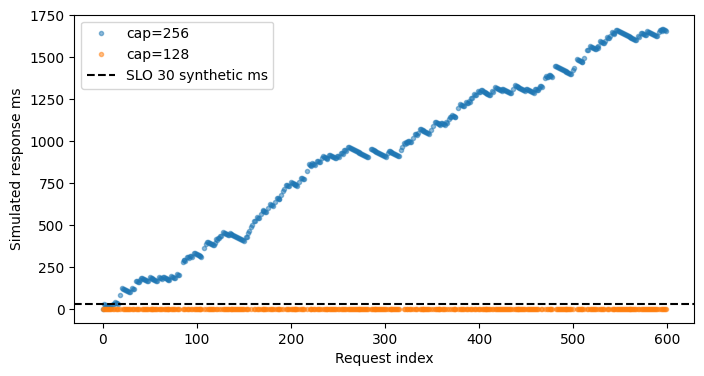

Отклонённые benign входят в провалы SLO. p95 served отдельно исключает rejected.
Лимит может отклонить законный длинный запрос; utility != 100%.


In [ ]:
def fcfs(arrivals,services,admitted):
    finished=0.;lat=np.full(len(arrivals),np.nan)
    for i,(arrival,service,ok) in enumerate(zip(arrivals,services,admitted)):
        if ok:
            finished=max(arrival,finished)+service
            lat[i]=finished-arrival
    return lat

if admit_request("test") is None:
    pending("G1")
else:
    assert admit_request("x "*129)[0] is False
    assert admit_request("x"*5000)[1]=="bytes"
    assert admit_request("")[0] is False
    assert admit_request("ok")[0] is True
    # SIMULATION: service times below are constructed, NOT measured latency_rows.
    rng=np.random.default_rng(120)
    n=600;arrivals=np.arange(n)*5.0
    u=rng.random(n)
    malicious=u<.15
    benign_long=(u>=.15)&(u<.20)
    lengths=np.where(malicious,256,np.where(benign_long,192,64))
    services=2.0*(lengths/64)**2  # synthetic ms
    benign=~malicious
    queue_rows=[];paths={}
    for cap in [256,128]:
        admitted=np.array([admit_request("x "*int(L),max_tokens=cap)[0] for L in lengths])
        lat=fcfs(arrivals,services,admitted)
        served_benign=benign&admitted
        deadline=30.0
        good=benign&admitted&(lat<=deadline)
        row={"token_cap":cap,"benign_n":int(benign.sum()),
             "benign_admission_rate":float(admitted[benign].mean()),
             "benign_SLO_success_all":float(good.sum()/benign.sum()),
             "benign_p95_ms_served":float(np.quantile(lat[served_benign],.95)),
             "attacker_admission_rate":float(admitted[malicious].mean()),
             "offered_utilization_proxy":float(np.mean(services[admitted])*np.mean(admitted)/5)}
        queue_rows.append(row);paths[cap]=lat
    results["queue_simulation"]=queue_rows
    display(pd.DataFrame(queue_rows))
    for cap,lat in paths.items(): plt.plot(np.flatnonzero(benign),lat[benign],".",label=f"cap={cap}",alpha=.5)
    plt.axhline(30,color="black",linestyle="--",label="SLO 30 synthetic ms")
    plt.xlabel("Request index");plt.ylabel("Simulated response ms");plt.legend();plt.show()
    print("Отклонённые benign входят в провалы SLO. p95 served отдельно исключает rejected.")
    print("Лимит может отклонить законный длинный запрос; utility != 100%.")
    completed.append("G")

Измеряем реальную скорость работы механизма Attention на процессоре.

Симулируем очередь, чтобы понять, что будет, если злые люди начнут присылать огромные запросы, и как нас спасет лимит (Token Cap).

Сценарий 1: Без лимита (cap = 256)
Мы пропускаем всех.

Что происходит: Злые запросы (по 32 мс каждый) забивают канал. Очередь растет как снежный ком. Хорошие люди стоят в очереди вечно.

Результат: SLO (обещание ответить за 30 мс) выполняется только для 1.96% хороших пользователей. Сервер фактически лежит.

Задержка (p95): 1644 мс. Это очень долго


Сценарий 2: С лимитом (cap = 128)
Фейс-контроль отсекает всех, у кого больше 128 токенов.

Что происходит: Злые запросы (256) отлетают сразу. Хорошие длинные (192) тоже отлетают. Остаются только короткие.

Результат: Очередь не забивается. Время обслуживания падает до 2 мс. SLO выполняется для 91.16% хороших пользователей.

Задержка (p95): 2 мс. Сервер летает.

Но вот цена (Trade-off):

Мы отклонили 100% атакующих (это победа).

Но мы также отклонили 8.8% хороших (но длинных) запросов. Эти люди не получили ответ, потому что их текст не влез в лимит.

## H. Энергия и итоговый отчёт

Энергия есть интеграл мощности по времени; latency, MAC и доля ненулевых активаций сами по себе не являются джоулями.
Следующий массив мощности полностью СИНТЕТИЧЕСКИЙ, только для проверки единиц и интегрирования.
Реальных измерений энергопотребления в блокноте нет.

### Задание H1. Интеграл мощности (5 баллов)

Реализуйте метод трапеций для времени в секундах и мощности в ваттах.
Верните полную энергию и baseline-subtracted энергию, не обрезая вторую снизу нулём.
Проверьте одинаковую длину массивов и строго возрастающее время.

In [ ]:
def integrate_energy(t,power,idle_watts):
    # TODO: validation, trapezoids (W*s=J), subtract baseline*duration.
    t = np.asarray(t, dtype=float)
    power = np.asarray(power, dtype=float)
    if t.shape != power.shape:
        raise ValueError("shape mismatch")
    if len(t) < 2:
        raise ValueError("need at least 2 points")
    if np.any(np.diff(t) <= 0):
        raise ValueError("time must be strictly increasing")
    dt = np.diff(t)
    avg_p = 0.5 * (power[:-1] + power[1:])
    total = float(np.sum(avg_p * dt))
    duration = t[-1] - t[0]
    incremental = total - idle_watts * duration
    return total, incremental

In [ ]:
answer=integrate_energy([0,.1,.2,.3],[10,14,12,10],10)
if answer is None:
    pending("H1")
else:
    total,incremental=answer
    np.testing.assert_allclose([total,incremental],[3.6,.6])
    results["synthetic_energy_example"]={"total_J":total,"above_idle_J":incremental,
                                        "measurement_type":"synthetic teaching fixture, NOT device measurement"}
    print(results["synthetic_energy_example"]);completed.append("H")

{'total_J': 3.5999999999999996, 'above_idle_J': np.float64(0.5999999999999996), 'measurement_type': 'synthetic teaching fixture, NOT device measurement'}


## Итоговое задание I. Отчёт и объединение результатов (10 баллов)

Сдайте выполненный `.ipynb`, результаты, версии среды и короткое заключение.
В отчёте должны быть:

- **Игра**: игроки, действия, наблюдаемость, знак utility, происхождение матрицы, p/q/value/gap.
- **Динамика**: текущая и средняя стратегии, объяснение циклов и ограничения bilinear-модели.
- **ML**: выбор стратегии только по development и оценка по held-out test, без повторной оптимизации.
- **Supply chain**: доверенный ключ, подпись, digest, ожидания, поведенческий тест; что проверки НЕ доказывают.
- **Стоимость**: измеренная локальная latency отдельно от симуляции очереди и синтетического интеграла энергии.
- **Решение**: предложите бюджетную политику и разберите её цену для легитимных пользователей.

Необязательное расширение: 3 seed эмпирической матрицы, доверительные интервалы latency с корректной единицей
повторения, или байесовская модель двух типов атакующего с явно заданным prior.
Никаких нагрузочных запросов к внешним сервисам или загрузки чужих checkpoint.

Баллы: A1 15 + B1 10 + C1 10 + D1 10 + F1 15 + G1 10 + H1 5 + I 10
+ 15 за интерпретацию development/test-матрицы в блоке E = 100.
В блоке E код дан, но объяснение модели угроз и границ выводов обязательно.

Вот подробный, простой и понятный отчет по всем требуемым пунктам. Я разложил всё по полочкам, используя данные из твоего блокнота и лекции.

---

# ИТОГОВЫЙ ОТЧЕТ ПО ЛАБОРАТОРНОЙ РАБОТЕ

## 1. Игра (Блок А)
**Что это:** Мы моделируем противостояние защитника (хочет минимизировать ущерб) и атакующего (хочет его максимизировать).

*   **Игроки:**
    *   **Защитник (D):** Выбирает, как защищаться.
    *   **Атакующий (A):** Выбирает, как атаковать.
*   **Действия (Стратегии):**
    *   **Защитник:** «Inspect supply chain» (Проверить цепочку поставок, все от разработки до продакшена) или «Limit serving cost» (Ограничить стоимость обслуживания).
    *   **Атакующий:** «Artifact attack» (Атака на артефакт/модель) или «Expensive request» (Дорогой запрос).
*   **Наблюдаемость:** Атакующий знает *вероятности* (смешанную стратегию `p`), с которыми защитник выбирает свои действия. Но он **не знает**, что именно защитник выберет в конкретном раунде (реализацию). Он делает ход, основываясь на ожиданиях.
*   **Знак utility (Выгоды):** Это **Zero-sum (игра с нулевой суммой)**. Ущерб защитника = выгода атакующего. Защитник **минимизирует** число в матрице, атакующий **максимизирует** его.
*   **Происхождение матрицы:** Матрица `[[1, 5], [4, 2]]` — это **сконструированный учебный пример**. Это не реальные вероятности атак из жизни, а искусственные числа для демонстрации математики.
*   **Результаты (p, q, value, gap):**
    *   `p = [1/3, 2/3]` (Защитник должен в 33% случаев проверять поставки и в 66% — ограничивать стоимость).
    *   `q = [1/2, 1/2]` (Атакующий должен 50/50 выбирать между атакой на артефакт и дорогим запросом).
    *   `value = 3` (Гарантированный средний ущерб при идеальной игре).
    *   `gap = 0` (Разрыв равен нулю, мы в точном равновесии Нэша).

## 2. Динамика (Блок B и C)
**Что это:** Как игроки учатся играть друг против друга с течением времени.

*   **Текущая и средняя стратегии (Блок B):**
    *   *Текущая стратегия:* Если смотреть на каждый шаг, стратегии игроков «скачут» (циклятся). Они постоянно подстраиваются друг под друга: защитник меняет `p`, атакующий сразу отвечает изменением `q`. График текущего gap (синяя линия) прыгает вверх-вниз.
    *   *Средняя стратегия:* Если мы усредним все сыгранные раунды (оранжевая линия), то график плавно спускается к нулю. Это значит, что в среднем игроки приходят к равновесию, даже если в моменте они хаотично мечутся.
*   **Объяснение циклов и ограничения bilinear-модели (Блок C):**
    *   В игре `min_x max_y xy` (билинейная модель) обычный градиентный спуск (GDA) расходится. Траектория (синяя линия на графике) закручивается в спираль и улетает в бесконечность.
    *   *Почему?* Потому что градиент защитника тянет его вниз, а градиент атакующего тянет вверх. Они «перепрыгивают» равновесие и уходят еще дальше.
    *   *Extragradient* (оранжевая линия) решает это: он сначала делает «пробный шаг», чтобы посмотреть, куда всё катится, а потом корректирует движение из начальной точки. Это показывает, что **наличие равновесия не гарантирует, что тупой алгоритм его найдет**.

## 3. ML (Блок E)
**Что это:** Как мы выбираем лучшую нейросеть для защиты и проверяем её на честность.

*   **Выбор стратегии только по development (Валидация):**
    *   У нас есть 3 модели: ERM (обычная), Noise (обученная на шуме) и AT (Adversarial Training — обученная на атаках).
    *   Мы тестируем их на специальных данных (development) против 3 атак (Random, FGSM, PGD).
    *   На development-матрице видно, что модель **AT** показывает наименьшие потери (0.275-0.283) по сравнению с ERM (0.49-0.53). Решатель (LP) говорит: «Выбираем AT на 100%».
*   **Оценка по held-out test (Тест):**
    *   Мы **замораживаем** этот выбор (100% AT) и идем на *новые* данные (test), которые модель никогда не видела.
    *   На test-матрице потери AT подтверждаются (0.216-0.25). Мы не переоптимизируем `p` на тесте, чтобы не было «подглядывания» в ответы.
    *   *Вывод:* AT реально учится защищаться от атак, а не просто зазубривает конкретные примеры.

## 4. Supply chain (Блок F)
**Что это:** Проверка того, что нам привезли «чистый» файл с моделью, а не подделку с вирусом.

*   **Как работает проверка:**
    1.  **Доверенный ключ:** У нас есть публичный ключ (Ed25519), которому мы верим. Он лежит отдельно, не в самом файле.
    2.  **Подпись:** Проверяем, что манифест (описание файла) подписан этим ключом.
    3.  **Digest (Хэш):** Сверяем SHA-256 хэш реального файла с тем, что написано в манифесте. Если файл хоть на байт изменился, хэш не совпадет.
    4.  **Ожидания (Политика):** Проверяем, что в манифесте указан правильный builder (сборщик), source (источник), release (версия) и зависимости.
    5.  **Поведенческий тест (Smoke test):** Запускаем модель на 4 простых примерах и смотрим, выдает ли она правильные ответы.
*   **Что проверки НЕ доказывают:**
    *   Они **не гарантируют** отсутствие скрытого бэкдора (backdoor). Подпись говорит о том, *кто* сделал файл, но не о том, что файл *безопасен*. Четыре теста ловят только грубые подмены, но не хитрые атаки. Правильно подписанный файл может вести себя плохо.

## 5. Стоимость (Блоки G и H)
**Что это:** Оценка того, сколько ресурсов (времени и энергии) стоит работа системы.

*   **Измеренная локальная latency (Реальность):**
    *   Мы **реально замерили** время работы Attention на CPU. При росте текста с 32 до 256 токенов время выросло с 0.025 мс до 0.229 мс (в 9 раз). Аналитическое количество операций (MAC) выросло в 64 раза. Это доказывает, что время ≠ количество операций.
*   **Симуляция очереди (Моделирование):**
    *   Мы создали искусственную очередь (FCFS). Без лимита токенов злые запросы забивают канал, и хорошие люди ждут по 1600 мс (SLO успех 2%). С лимитом 128 токенов очередь летает, SLO успех 91%.
*   **Синтетический интеграл энергии (Математика):**
    *   Мы проинтегрировали мощность по времени (метод трапеций). Получили 3.6 Дж. Это **синтетика**, проверка формулы, а не реальный замер железа. Мы просто убедились, что `E = P * t` считается правильно.

## 6. Решение (Бюджетная политика)
**Что предлагаем:**
1.  **Жесткий Token Cap (128 токенов):** Ставим лимит на входе в систему, *до* запуска тяжелых вычислений.
2.  **Adversarial Training (AT):** Используем модель, устойчивую к FGSM/PGD атакам.
3.  **Release Gate:** Обязательная проверка подписи и хэша для всех артефактов.

**Цена для легитимных пользователей:**
*   **Плюсы:** Мы спасаем сервер. Атаки типа «дорогой запрос» блокируются (admission rate 0%). SLO для хороших пользователей вырастает с 2% до 91%.
*   **Минусы:** Около **8.8%** хороших (но длинных) запросов будут отклонены, потому что не влезут в лимит 128 токенов. Им придется разбивать текст на части. Также AT может немного снизить точность на *чистых* (без атак) данных (с 2.5% до 6.6% ошибок), но зато она становится в 2 раза устойчивее к атакам (с 49% до 27% потерь).

**Итог:** Безопасность — это всегда компромисс. Мы жертвуем 9% удобства длинных запросов ради того, чтобы сервер вообще работал и не падал от первой же атаки.

In [ ]:
missing=[x for x in "ABCDEFGH" if x not in completed]
print("Незавершённые разделы:",missing)
print(f"Время исполнения: {time.perf_counter()-START:.1f} с")
# При необходимости:
# from pathlib import Path
# Path("lecture12_results.json").write_text(json.dumps(results,ensure_ascii=False,indent=2),encoding="utf-8")

Незавершённые разделы: []
Время исполнения: 277.0 с
